# EXOVEL Sweet-Spot Scatter Maps

Interactive version of `scripts/paper_snr_scatter_maps.py`. Use this notebook to tune labels, font sizes, marker sizes, color ranges, and output names for the paper figure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Robust project-root detection when the notebook is opened from Jupyter.
cwd = Path.cwd().resolve()
if (cwd / "src" / "xds").exists():
    ROOT = cwd
elif (cwd.parent / "src" / "xds").exists():
    ROOT = cwd.parent
else:
    ROOT = Path("/Users/sucerqum/Documents/Playground/xds")

OUTPUTS = ROOT / "outputs"
print(ROOT)


/Users/sucerqum/Documents/Playground/xds


## Figure Controls

In [75]:
# Input from the LHS sweet-spot refinement.
data_path = OUTPUTS / "xds_lhs_refined_lhs100k_ref1500_seed11.npz"

# Output names. Keep xds in filenames if useful for provenance, but use EXOVEL in the figure text.
output_png = OUTPUTS / "exovel_paper_snr_scatter_maps_lhs100k_ref1500_seed11.png"
output_pdf = OUTPUTS / "exovel_paper_snr_scatter_maps_lhs100k_ref1500_seed11.pdf"

# Text and style knobs.
observable_name = ""
font_scale = 1.20
figsize = (8.0, 6.7)
dpi = 600

# Marker and color controls.
snr_threshold = 5.0
snr_vmin = 5.0
snr_vmax = 27.0
n_highlight = 20
background_size = 12
detectable_size = 40
highlight_size = 78
highlight_color = "#19bff2"
detectable_cmap = "plasma"

# Global matplotlib typography.
base = 9.0 * font_scale
plt.rcParams.update(
    {
        "font.size": base,
        "axes.labelsize": base,
        "axes.titlesize": 11.5 * font_scale,
        "xtick.labelsize": 8.8 * font_scale,
        "ytick.labelsize": 8.8 * font_scale,
        "legend.fontsize": 8.5 * font_scale,
        "axes.linewidth": 1.0,
        "xtick.major.width": 1.0,
        "ytick.major.width": 1.0,
        "xtick.major.size": 4.5,
        "ytick.major.size": 4.5,
    }
)


## Load Data

In [71]:
if not data_path.exists():
    raise FileNotFoundError(data_path)

data = np.load(data_path)
snr = data["snr"]
detectable = np.flatnonzero(snr >= snr_threshold)
top = detectable[np.argsort(snr[detectable])[::-1]][:n_highlight]

if "density_g_cm3" in data.files:
    density = data["density_g_cm3"]
else:
    density = 1.326 * data["planet_mass_jupiter"] / data["planet_radius_jupiter"] ** 3

pm_over_tdur = data["moon_period_hours"] / data["transit_duration_hours"]

print(f"systems: {snr.size}")
print(f"detectable SNR >= {snr_threshold:g}: {detectable.size}")
print(f"max SNR: {np.nanmax(snr):.2f}")


systems: 1500
detectable SNR >= 5: 268
max SNR: 83.16


## Plot Helpers

In [72]:
def draw_panel(ax, x, y, snr, top, xlabel, ylabel, title, xscale=None, xlim=None, ylim=None):
    low = snr < snr_threshold
    high = snr >= snr_threshold
    ax.scatter(
        x[low],
        y[low],
        s=background_size,
        c="#c9c9c9",
        alpha=0.35,
        linewidths=0.01,
        rasterized=True,
    )
    sc = ax.scatter(
        x[high],
        y[high],
        s=0.5*detectable_size,
        c=snr[high],
        cmap=detectable_cmap,
        vmin=snr_vmin,
        vmax=snr_vmax,
        edgecolors="black",
        linewidths=0.06,
        rasterized=True,
        alpha=0.8,
    )
    ax.scatter(
        x[top],
        y[top],
        s=highlight_size,
        facecolors="none",
        edgecolors=highlight_color,
        linewidths=1.1,
    )
    if xscale:
        ax.set_xscale(xscale)
    if xlim:
        ax.set_xlim(*xlim)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_xlabel(xlabel, fontsize=fs)
    ax.set_ylabel(ylabel, fontsize=fs)
    ax.set_title(title, fontsize=fs)
    ax.tick_params(direction="in", top=True, right=True)
    return sc


## Make Figure

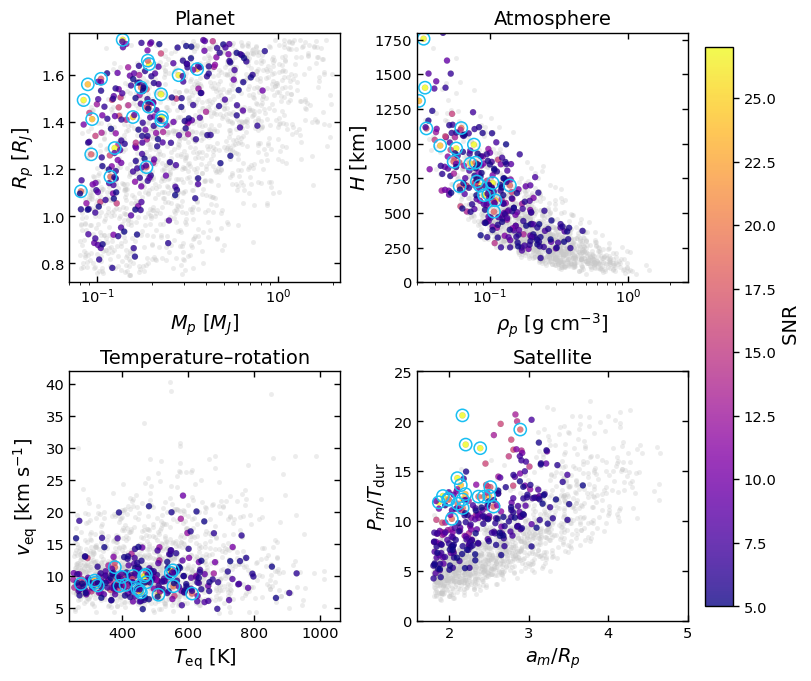

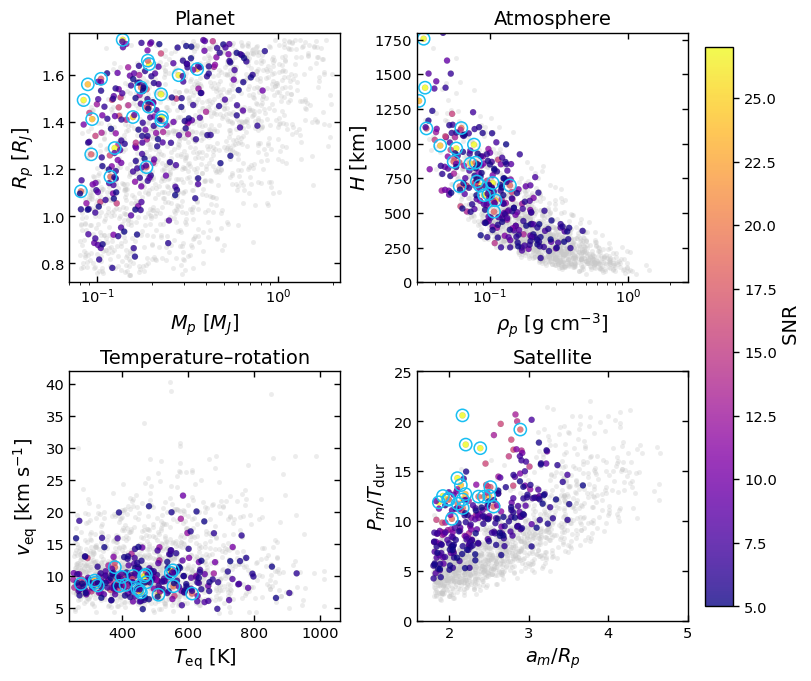

In [76]:
fig, axes = plt.subplots(2, 2, figsize=figsize, constrained_layout=True)
fs=14
sc = draw_panel(
    axes[0, 0],
    data["planet_mass_jupiter"],
    data["planet_radius_jupiter"],
    snr,
    top,
    r"$M_p$ [$M_J$]",
    r"$R_p$ [$R_J$]",
    "Planet",
    xscale="log",
    xlim=(0.07, 2.2),
    ylim=(0.72, 1.78),
)
draw_panel(
    axes[0, 1],
    density,
    data["scale_height_km"],
    snr,
    top,
    r"$\rho_p$ [g cm$^{-3}$]",
    r"$H$ [km]",
    "Atmosphere",
    xscale="log",
    xlim=(0.03, 2.7),
    ylim=(0, 1800),
)
draw_panel(
    axes[1, 0],
    data["temperature_k"],
    data["v_eq_km_s"],
    snr,
    top,
    r"$T_{\rm eq}$ [K]",
    r"$v_{\rm eq}$ [km s$^{-1}$]",
    "Temperature–rotation",
    xlim=(240, 1060),
    ylim=(3, 42),
)
draw_panel(
    axes[1, 1],
    data["moon_separation_rp"],
    pm_over_tdur,
    snr,
    top,
    r"$a_m/R_p$",
    r"$P_m/T_{\rm dur}$",
    "Satellite",
    xlim=(1.6, 5),
    ylim=(0, 25),
)

cbar = fig.colorbar(sc, ax=axes, shrink=0.95, pad=0.02)
cbar.set_label(f"{observable_name} SNR", fontsize=fs)
fig


## Save

In [77]:
fig.savefig(output_png, dpi=dpi)
fig.savefig(output_pdf)
print(output_png)
print(output_pdf)


/Users/sucerqum/Documents/Playground/xds/outputs/exovel_paper_snr_scatter_maps_lhs100k_ref1500_seed11.png
/Users/sucerqum/Documents/Playground/xds/outputs/exovel_paper_snr_scatter_maps_lhs100k_ref1500_seed11.pdf
